# Credit Default Classification

## Background and Problem

## Data Description

## Preparation and Feature Generation

First we load in the necessary packages for our analysis:

In [47]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.feature_selection import SelectFromModel
from sklearn.linear_model import LogisticRegression

Then we load in the credit default dataset:

In [58]:
default = pd.read_csv('default.csv')
default.head()

,Unnamed: 0,X1,X2,X3,X4,X5,X6,X7,X8,X9,...,X15,X16,X17,X18,X19,X20,X21,X22,X23,Y
0,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default payment next month
1,1,20000,2,2,1,24,2,2,-1,-1,...,0,0,0,0,689,0,0,0,0,1
2,2,120000,2,2,2,26,-1,2,0,0,...,3272,3455,3261,0,1000,1000,1000,0,2000,1
3,3,90000,2,2,2,34,0,0,0,0,...,14331,14948,15549,1518,1500,1000,1000,1000,5000,0
4,4,50000,2,2,1,37,0,0,0,0,...,28314,28959,29547,2000,2019,1200,1100,1069,1000,0


We get rid of the extra column labels on the top and instead use the more descriptive first row as column labels. We also ensure all columns are read as numeric for now:

In [59]:
default.columns = default.iloc[0]
default = default[1:]
default.reset_index(drop = True, inplace = True)
default = default.apply(pd.to_numeric, errors = 'coerce')
default.head()

,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default payment next month
0,1,20000,2,2,1,24,2,2,-1,-1,...,0,0,0,0,689,0,0,0,0,1
1,2,120000,2,2,2,26,-1,2,0,0,...,3272,3455,3261,0,1000,1000,1000,0,2000,1
2,3,90000,2,2,2,34,0,0,0,0,...,14331,14948,15549,1518,1500,1000,1000,1000,5000,0
3,4,50000,2,2,1,37,0,0,0,0,...,28314,28959,29547,2000,2019,1200,1100,1069,1000,0
4,5,50000,1,2,1,57,-1,0,-1,0,...,20940,19146,19131,2000,36681,10000,9000,689,679,0


ID will not provide us any useful information in predicting defaults, so we drop it:

In [60]:
default = default.drop(columns = ['ID'])

We check for NaN's and split by column:

In [61]:
print(default.isna().sum())

0
LIMIT_BAL                     0
SEX                           0
EDUCATION                     0
MARRIAGE                      0
AGE                           0
PAY_0                         0
PAY_2                         0
PAY_3                         0
PAY_4                         0
PAY_5                         0
PAY_6                         0
BILL_AMT1                     0
BILL_AMT2                     0
BILL_AMT3                     0
BILL_AMT4                     0
BILL_AMT5                     0
BILL_AMT6                     0
PAY_AMT1                      0
PAY_AMT2                      0
PAY_AMT3                      0
PAY_AMT4                      0
PAY_AMT5                      0
PAY_AMT6                      0
default payment next month    0
dtype: int64


Now we will create some potentially useful features from the data that can generalize some columns and highlight potentially relevant behavior from others:

- Late months: How many months was the client late on their payment?
- Average bill: What was the average of bill amounts?
- Average utilization: Average bill over the users' credit limit.
- Max utilization: Maximum utilization over the time period.
- Average payment: What was the average of the payment amounts?
- Payment ratio: Average payment over average bill.
- Max delay:
- Recent late:

In [62]:
default['LATE_MONTHS'] = (default[['PAY_0', 'PAY_2', 'PAY_3', 'PAY_4', 'PAY_5', 'PAY_6']] > 0).sum(axis = 1)
default['AVG_BILL'] = (default['BILL_AMT1'] + default['BILL_AMT2'] + default['BILL_AMT3'] + default['BILL_AMT4'] + default['BILL_AMT5'] + default['BILL_AMT6']) / 6
default['AVG_UTILIZATION'] = default['AVG_BILL'] / default['LIMIT_BAL']
default['AVG_PAYMENT'] = (default['PAY_AMT1'] + default['PAY_AMT2'] + default['PAY_AMT3'] + default['PAY_AMT4'] + default['PAY_AMT5'] + default['PAY_AMT6']) / 6
default['MAX_DELAY'] = default[['PAY_0', 'PAY_2', 'PAY_3', 'PAY_4', 'PAY_5', 'PAY_6']].max(axis = 1)
default['RECENT_LATE'] = (default[['PAY_0', 'PAY_2', 'PAY_3']] > 0).sum(axis = 1)
default['PAYMENT_RATIO'] = default['AVG_PAYMENT'] / default['AVG_BILL']
default['MAX_UTILIZATION'] = default[['BILL_AMT1', 'BILL_AMT2', 'BILL_AMT3', 'BILL_AMT4', 'BILL_AMT5', 'BILL_AMT6']].max(axis = 1) / default['LIMIT_BAL'].replace(0, np.nan)

In [63]:
print('NaN:', default.isna().sum() + np.isposinf(default).sum() + np.isneginf(default).sum())

NaN: 0
LIMIT_BAL                       0
SEX                             0
EDUCATION                       0
MARRIAGE                        0
AGE                             0
PAY_0                           0
PAY_2                           0
PAY_3                           0
PAY_4                           0
PAY_5                           0
PAY_6                           0
BILL_AMT1                       0
BILL_AMT2                       0
BILL_AMT3                       0
BILL_AMT4                       0
BILL_AMT5                       0
BILL_AMT6                       0
PAY_AMT1                        0
PAY_AMT2                        0
PAY_AMT3                        0
PAY_AMT4                        0
PAY_AMT5                        0
PAY_AMT6                        0
default payment next month      0
LATE_MONTHS                     0
AVG_BILL                        0
AVG_UTILIZATION                 0
AVG_PAYMENT                     0
MAX_DELAY                       0
RECENT_

In [64]:
default = default.replace([np.inf, -np.inf], np.nan)
default = default.dropna()

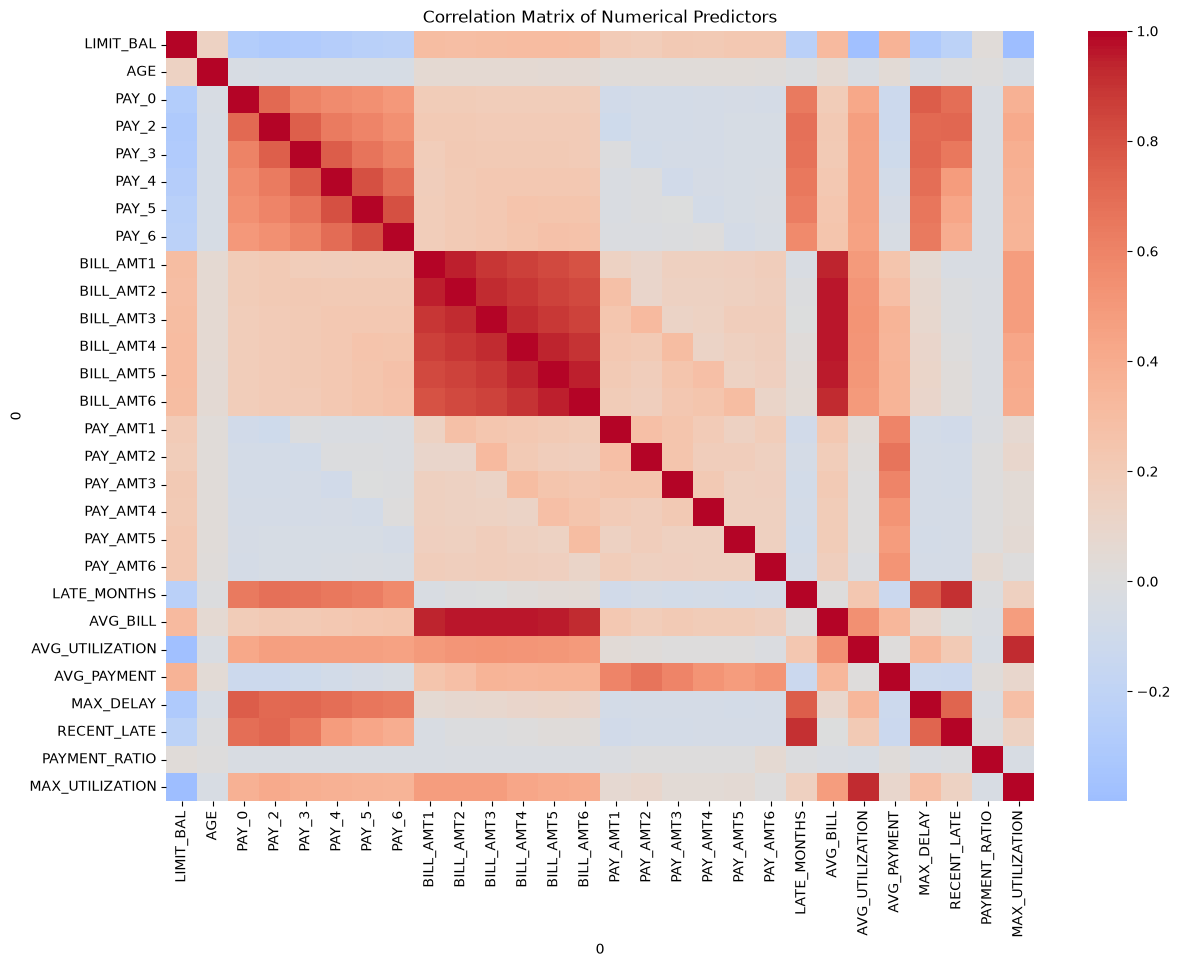

In [65]:
numerical = default.drop(columns = ['SEX', 'EDUCATION', 'MARRIAGE', 'default payment next month'])
plt.figure(figsize = (14, 10))
sns.heatmap(numerical.corr(), cmap = 'coolwarm', center = 0)
plt.title('Correlation Matrix of Numerical Predictors')
plt.show()

In [68]:
default = default.drop(columns = ['BILL_AMT1', 'BILL_AMT2', 'BILL_AMT3', 'BILL_AMT4', 'BILL_AMT5', 'BILL_AMT6'])

In [69]:
default.loc[~default['EDUCATION'].isin([1, 2, 3, 4]), 'EDUCATION'] = 4
default.loc[~default['MARRIAGE'].isin([1, 2, 3]), 'MARRIAGE'] = 3

In [84]:
# Separate predictors and response
X = default.drop(columns = ['default payment next month'])
y = default['default payment next month']

# Split data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state = 42)

# One-hot encode categorical variables
X_train = pd.get_dummies(X_train, columns = ['SEX', 'EDUCATION', 'MARRIAGE'], dtype = int)
X_test = pd.get_dummies(X_test, columns = ['SEX', 'EDUCATION', 'MARRIAGE'], dtype = int)
X_test = X_test.reindex(columns = X_train.columns, fill_value = 0)

# Standardize predictors
scaler = StandardScaler()
X_train = pd.DataFrame(scaler.fit_transform(X_train), columns = X_train.columns, index = X_train.index)
X_test = pd.DataFrame(scaler.transform(X_test), columns = X_test.columns, index = X_test.index)

## Model 1: Logistic Regression

## Model 2: Support Vector Machine

## Model 3: Perceptron Classifier

## Comparison and Evaluation

## Conclusion

## References